# Confusion Matrix & Classification Metrics

**Goal:** Master precision, recall, F1, and the confusion matrix — and learn when to use each.

**Why it matters:**
- **Accuracy lies on imbalanced data.** A 99% accuracy can mean "predicted the majority class always".
- Different business problems care about different errors: a cancer screening and a spam filter optimize different metrics.
- These metrics are the language of model evaluation in every serious ML project.

**Prerequisite:** [01-overfitting-underfitting.ipynb](./01-overfitting-underfitting.ipynb)

**Dataset:** Titanic (imbalanced), plus a synthetic highly-imbalanced example.

---

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    precision_recall_curve, roc_curve, average_precision_score,
    ConfusionMatrixDisplay,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
np.random.seed(42)

print("Setup complete.")

Setup complete.


## The Accuracy Trap

Imagine a disease that affects 1% of the population. A model that always predicts "healthy":
- Accuracy = 99% (looks amazing!)
- Recall for the "diseased" class = 0% (catches zero sick people)
- Useless in practice.

This is the **accuracy paradox**: on imbalanced data, accuracy rewards the trivial "always predict majority" classifier.

### The Confusion Matrix

For binary classification:

|                | Predicted Negative | Predicted Positive |
|----------------|--------------------|--------------------|
| **Actual Negative** | TN (True Negative) | FP (False Positive) — Type I |
| **Actual Positive** | FN (False Negative) — Type II | TP (True Positive) |

All classification metrics are functions of these four numbers.

In [11]:
np.random.seed(42)
n = 10_000
y_imb = np.random.choice([0,1], size=n, p=[0.99, 0.01])
y_pred_dumb = np.zeros_like(y_imb)

print("=== Always-predict-0 model on 1% positive data ===")
print(f"Accuracy : {accuracy_score(y_imb, y_pred_dumb):.4f}")
print(f"Precision: {precision_score(y_imb, y_pred_dumb, zero_division=0):.4f}")
# zero_division=0 → handle the case where denominator is 0.

print(f"Recall   : {recall_score(y_imb, y_pred_dumb, zero_division=0):.4f}")
print(f"F1       : {f1_score(y_imb, y_pred_dumb, zero_division=0):.4f}")


=== Always-predict-0 model on 1% positive data ===
Accuracy : 0.9914
Precision: 0.0000
Recall   : 0.0000
F1       : 0.0000


- Accuracy = (TP + TN) / (TP + TN + FP + FN) Accuracy (دقت کلی)

- Precision = TP / (TP + FP) «از کل پیش‌بینی‌ها، چند درصد درست بود؟»  

- Recall = TP / (TP + FN) «از هر چیزی که گفتم مثبت است، چند تا واقعاً مثبت بود؟»  

- F1 = 2 · (Precision · Recall) / (Precision + Recall) «از هر چیزی که واقعاً مثبت بود، چند تا را گرفتم؟»  



In [12]:
# Load Titanic (cleaned)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

df["HasCabin"] = df["Cabin"].notna().astype(int)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda x: x.fillna(x.median()))
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch",
         "Fare", "Embarked", "HasCabin", "FamilySize", "IsAlone"]]

X = df.drop(columns=["Survived"])
y = df["Survived"]

numeric_features = ["Age", "SibSp", "Parch", "Fare", "HasCabin", "FamilySize", "IsAlone"]
categorical_features = ["Pclass", "Sex", "Embarked"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), categorical_features),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train logistic regression
clf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion Matrix:\n{cm}")
print(f"\nTN={tn}, FP={fp}, FN={fn}, TP={tp}")

Confusion Matrix:
[[97 13]
 [21 48]]

TN=97, FP=13, FN=21, TP=48


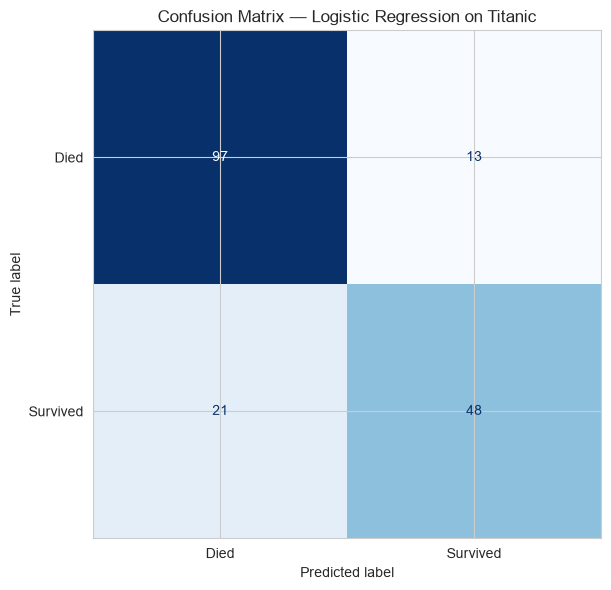

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
  confusion_matrix=cm,
  display_labels=["Died", "Survived"],
).plot(
  cmap="Blues",
  ax=ax,
  colorbar=False,
  values_format="d",
)

ax.set_title("Confusion Matrix — Logistic Regression on Titanic")
plt.tight_layout()
plt.show()

In [14]:
# Compute metrics manually — to see how each is derived
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * (precision * recall) / (precision + recall)

print("Manual calculations:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1       : {f1:.4f}")

# Compare with sklearn (should match)
print("\nsklearn calculations:")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1       : {f1_score(y_test, y_pred):.4f}")

Manual calculations:
Accuracy : 0.8101
Precision: 0.7869
Recall   : 0.6957
F1       : 0.7385

sklearn calculations:
Accuracy : 0.8101
Precision: 0.7869
Recall   : 0.6957
F1       : 0.7385


## Classification Report — All Metrics at Once

`classification_report` prints precision, recall, F1, and support (count) for EACH class.

**Two averaging modes:**
- **Macro avg** — unweighted mean of per-class metrics. Treats classes equally.
- **Weighted avg** — mean weighted by support. Reflects overall performance.

**When do they differ?** On imbalanced data. The minority class pulls macro down, but weighted hides it.

**Rule:** On imbalanced data, always report **per-class metrics** and **macro avg**, not just weighted avg.

 zero_division=0 → handle the case where denominator is 0.
   - 0: return 0 (silently)
   - 1: return 1 (misleading!)
   - "warn": return 0 and warn
   Use 0 in production; use "warn" during development to catch bugs.

In [15]:
print(classification_report(
  y_test, y_pred,
  target_names=["Died", "Survived"],
  digits=4,
  zero_division=0,
))


              precision    recall  f1-score   support

        Died     0.8220    0.8818    0.8509       110
    Survived     0.7869    0.6957    0.7385        69

    accuracy                         0.8101       179
   macro avg     0.8045    0.7887    0.7947       179
weighted avg     0.8085    0.8101    0.8075       179



## Choosing the Right Metric — Decision Guide

| If your problem is... | Metric to optimize |
|------------------------|--------------------|
| Balanced classes | **Accuracy** |
| Costly False Positives | **Precision** |
| Costly False Negatives | **Recall** |
| Both matter, imbalance | **F1** |
| Ranking / probability quality | **ROC-AUC** |
| Imbalance + probability quality | **PR-AUC (Average Precision)** |

### Real-world examples

| Problem | Optimize | Why |
|---------|----------|-----|
| Spam filter | Precision | Don't block legit emails |
| Cancer screening | Recall | Don't miss sick patients |
| Fraud detection | Recall + Precision | Both errors costly |
| Credit approval | Precision | Don't reject good customers |
| Search ranking | ROC-AUC | Rank ordering matters |
| Object detection | mAP | Combines precision/recall |

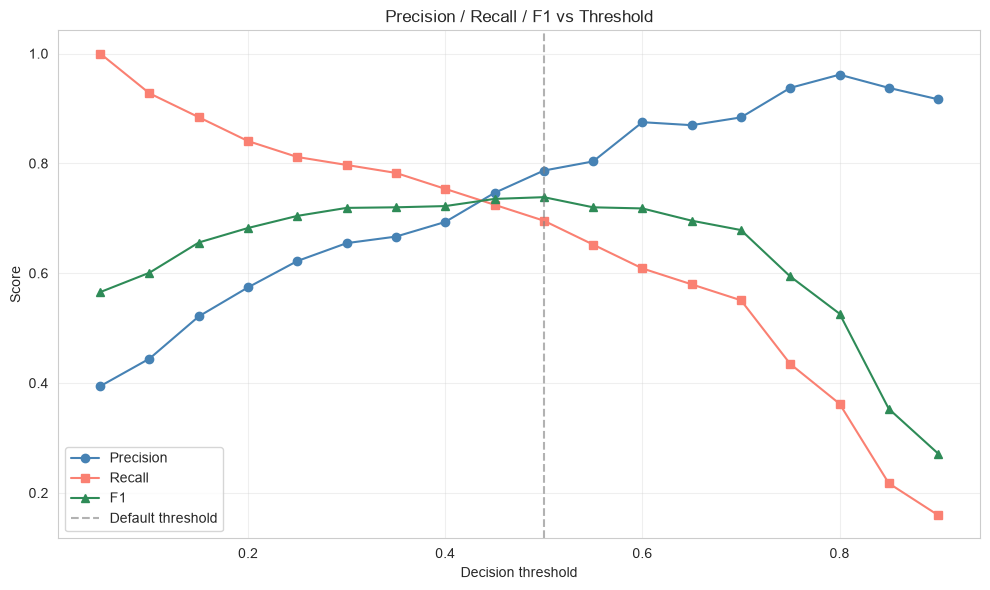

Best F1 threshold: 0.5 → F1 = 0.7385


In [16]:
# Vary decision threshold to see precision/recall tradeoff
thresholds = np.arange(0.05, 0.95, 0.05)
rows = []

for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    # y_proba ≥ t → predicted positive.
    #   - Lower threshold → more positives → recall ↑, precision ↓
    #   - Higher threshold → fewer positives → precision ↑, recall ↓
    rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_test, y_pred_t, zero_division=0),
        "Recall":    recall_score(y_test, y_pred_t, zero_division=0),
        "F1":        f1_score(y_test, y_pred_t, zero_division=0),
    })

thr_df = pd.DataFrame(rows)

plt.figure(figsize=(10, 6))
plt.plot(thr_df["Threshold"], thr_df["Precision"], "o-", label="Precision", color="steelblue")
plt.plot(thr_df["Threshold"], thr_df["Recall"],    "s-", label="Recall",    color="salmon")
plt.plot(thr_df["Threshold"], thr_df["F1"],        "^-", label="F1",        color="seagreen")
plt.axvline(0.5, color="gray", linestyle="--", alpha=0.6, label="Default threshold")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs Threshold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Best F1 threshold
best_row = thr_df.loc[thr_df["F1"].idxmax()]
print(f"Best F1 threshold: {best_row['Threshold']} → F1 = {best_row['F1']:.4f}")

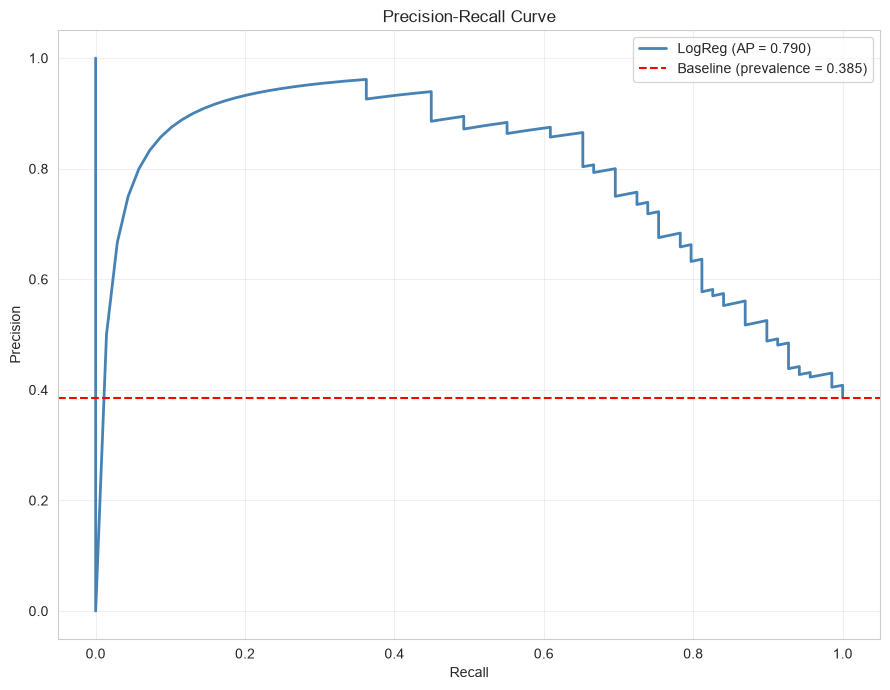

In [17]:
precisions, recalls, thresholds_pr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

plt.figure(figsize=(9, 7))
plt.plot(recalls, precisions, linewidth=2, color="steelblue",
         label=f"LogReg (AP = {ap:.3f})")
plt.axhline(y=y_test.mean(), color="red", linestyle="--",
            label=f"Baseline (prevalence = {y_test.mean():.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


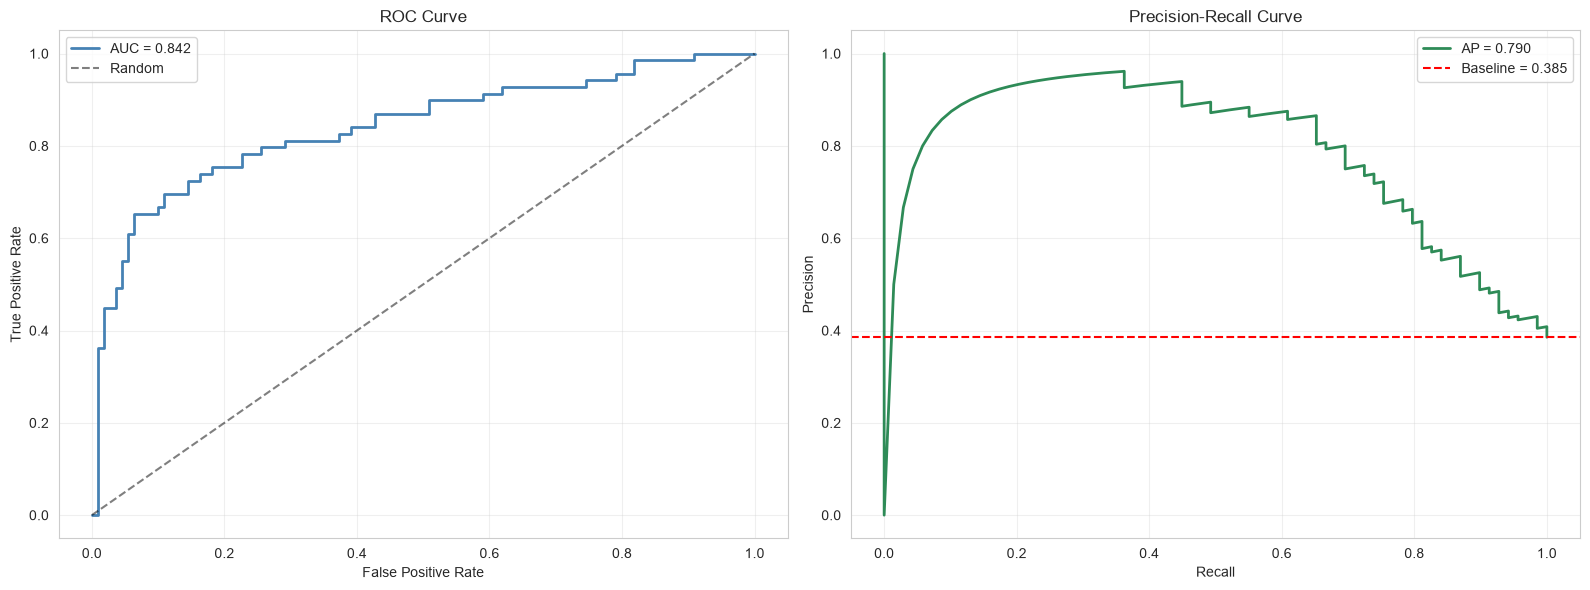

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

axes[0].plot(fpr, tpr, linewidth=2, color="steelblue", label=f"AUC = {auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# PR
axes[1].plot(recalls, precisions, linewidth=2, color="seagreen", label=f"AP = {ap:.3f}")
axes[1].axhline(y=y_test.mean(), color="red", linestyle="--",
                label=f"Baseline = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Summary

### The four core metrics

| Metric | Formula | Optimize when |
|--------|---------|---------------|
| Accuracy | (TP+TN) / all | Balanced classes |
| Precision | TP / (TP+FP) | False Positives costly |
| Recall | TP / (TP+FN) | False Negatives costly |
| F1 | 2PR/(P+R) | Balance + imbalance |

### The critical rules

1. **Never trust accuracy alone on imbalanced data.**
2. **Always report per-class metrics** alongside averages.
3. **Tune the threshold** — 0.5 is a default, not a law.
4. **Use PR-AUC** when positives are rare (<10%).
5. **Match the metric to the business cost** of each error type.

## 🚀 Next

→ [03-roc-auc-learning-curve.ipynb](./03-roc-auc-learning-curve.ipynb): deeper dive into ROC-AUC and learning curves.

In [19]:
import joblib
joblib.dump(clf, "logreg_titanic_eval.joblib")
print("Saved: logreg_titanic_eval.joblib")

Saved: logreg_titanic_eval.joblib
